Spectrum of Sodium-22

In [199]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [200]:
with open("spectrum_paddenstoelen_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [201]:
pulseheight = []
counts = []
for i in range(16, 160):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

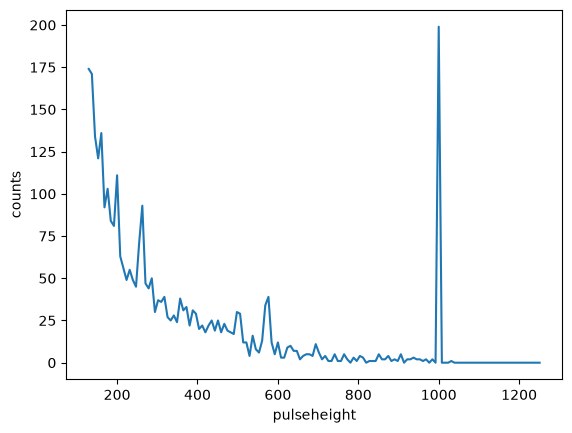

In [202]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [203]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1, x02, a2, gam2, x03, a3, gam3):#, x04, a4, gam4):
    return lorentzian(x, x01, a1, gam1) + lorentzian(x, x02, a2, gam2) + lorentzian(x, x03, a3, gam3) #+ lorentzian(x, x04, a4, gam4)

In [204]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=220, a1=200, gam1=10, x02=600, a2=200, gam2=10, x03=260, a3=200, gam3=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 4906
    # data points      = 144
    # variables        = 9
    chi-square         = 43365.3938
    reduced chi-square = 321.225140
    Akaike info crit   = 839.894936
    Bayesian info crit = 866.623256
    R-squared          = 0.77340383
[[Variables]]
    x01:  -13.3175691 +/- 93.4526252 (701.72%) (init = 220)
    a1:    602780.431 +/- 1.9352e+09 (321052.13%) (init = 200)
    gam1: -2.43228935 +/- 3924.57849 (161353.27%) (init = 10)
    x02:   572.754358 +/- 1.39426843 (0.24%) (init = 600)
    a2:    253138.926 +/- 1.1783e+10 (4654827.10%) (init = 200)
    gam2: -0.03937908 +/- 921.445592 (2339936.96%) (init = 10)
    x03:   259.636443 +/- 3.55157710 (1.37%) (init = 260)
    a3:    370551.632 +/- 1.8848e+10 (5086415.21%) (init = 200)
    gam3: -0.03461774 +/- 885.120783 (2556841.50%) (init = 10)
[[Correlations]] (unreported correlations are < 0.100)
    C(a2, gam2)  

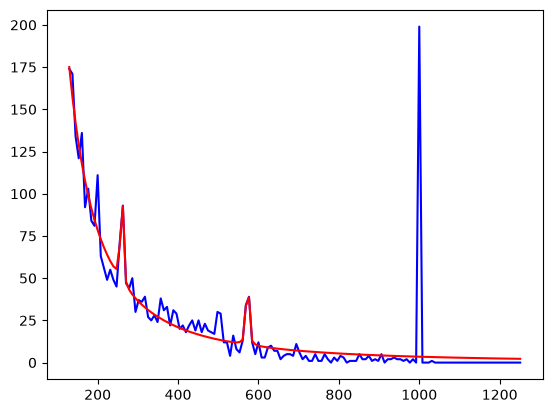

In [205]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [207]:
pulseheight1 = fit_result.params['x01'].value
pulseheight2 = fit_result.params['x02'].value
pulseheight3 = fit_result.params['x03'].value
# pulseheight4 = fit_result.params['x04'].value

err_1 = fit_result.params['x01'].stderr
err_2 = fit_result.params['x02'].stderr
err_3 = fit_result.params['x03'].stderr
# err_4 = fit_result.params['x04'].stderr

print(pulseheight1, err_1)
print(pulseheight2, err_2)
print(pulseheight3, err_3)
# print(pulseheight4, err_4)

-13.317569061423683 93.4526252081534
572.7543581932806 1.394268431524594
259.6364434387644 3.551577101007459


In [211]:
energy2 = 2.98359957 * pulseheight2 - 65.6423766
energy3 = 2.98359957 * pulseheight3 - 65.6423766

err3 = 2.98359957 * err_3 - 65.6423766
err2 = 2.98359957 * err_2 - 65.6423766

print(energy2, err2, energy3, err3)

1643.227280221098 -61.482437907238655 709.0088044002267 -55.045892688612305
